## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

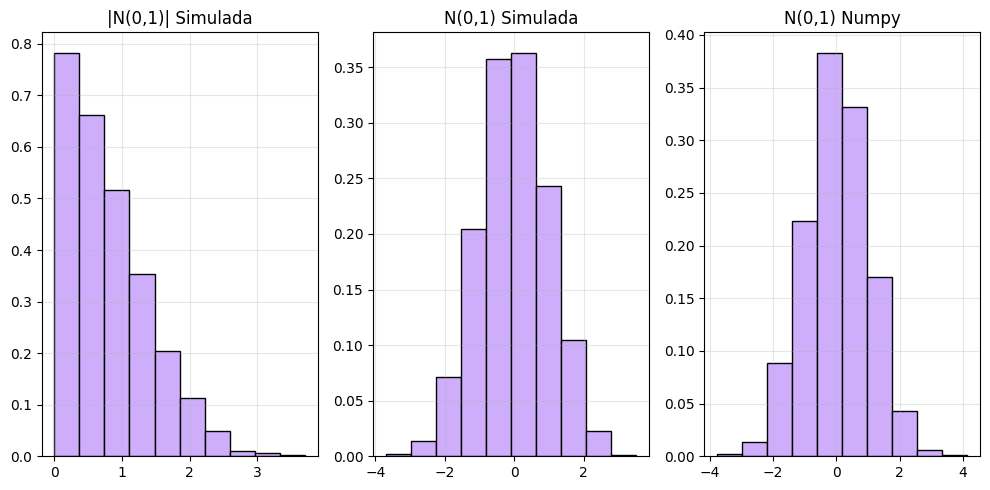

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

lmb_exp = 1
n_amostra = 5000
propostas = [] # lista que vai conter a quantidade de tentativas até aceitar um valor para cada ponto gerado no método

def f(x): # *2 porque é uma normal padrão definida em x > 0 (ficando apenas meia normal)
  return 2 * ((1/np.sqrt(2*np.pi))*np.e**(-(x**2)/2))

def g(x):
  return np.exp(-x)

def exp(lmb):
  u = np.random.uniform(0, 1)
  return -np.log(u) / lmb

c = 1.3154 # Calculado via análise da função de maneira teórica (derivar e achar o máx.)

def geraPontoX():
  i = 0
  while True:
    i += 1
    y = exp(lmb_exp)
    if np.random.uniform(0,1) < (f(y)/(g(y)*c)):
      propostas.append(i)
      return y


#sinais = [-1 if x < 0.5 else 1 for x in (np.random.uniform(0,1, size= n_amostra))]
sinais = np.where(np.random.uniform(0, 1, size=n_amostra) < 0.5, -1, 1) # solução vetorizada 😎

a = []
for _ in range(n_amostra):
  a.append(geraPontoX())
a = np.array(a)

a_normal_padrao = a * sinais

#a_normal = transformarNormal(a, mu_normal, sigma_normal)

normal_padrao_np = np.random.normal(0, 1, size=n_amostra)

fig, axs = plt.subplots(1, 3, tight_layout=True, figsize=(10, 5)) # https://matplotlib.org/stable/gallery/statistics/hist.html
axs[0].hist(a, density=True, color="xkcd:pale violet", edgecolor='black')
axs[0].set(title="|N(0,1)| Simulada")

axs[1].hist(a_normal_padrao, density=True, color="xkcd:pale violet", edgecolor='black')
axs[1].set(title="N(0,1) Simulada")

axs[2].hist(normal_padrao_np, density=True, color="xkcd:pale violet", edgecolor='black')
axs[2].set(title="N(0,1) Numpy")

axs[0].grid(True, alpha=0.3)
axs[1].grid(True, alpha=0.3)
axs[2].grid(True, alpha=0.3)

plt.show()



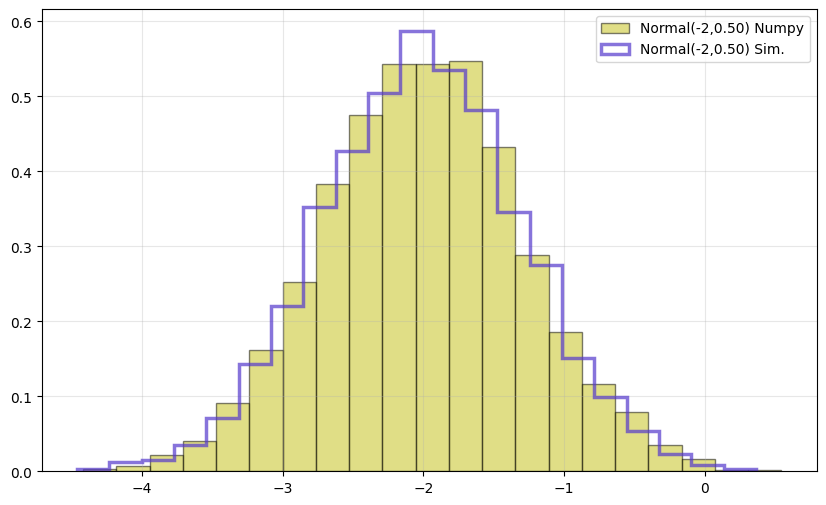

In [ ]:
mu_normal = -2
sigma_normal = (0.5)**(1/2)
n_amostra = 5000

def transformarNormal(amostra, mu, sigma):
    return np.array(amostra) * sigma + mu

def amostraNormalPadrao(n):
  amostra = []
  for _ in range(n):
    amostra.append(geraPontoX())
  amostra = np.array(amostra)

  sgn = np.where(np.random.uniform(0, 1, size=n) < 0.5, -1, 1) # solução vetorizada 😎
  return amostra * sgn

def amostraNormal(n, mu, sigma):
  amostra_n_padrao = amostraNormalPadrao(n)

  return transformarNormal(amostra_n_padrao, mu, sigma)


normal_np = np.random.normal(mu_normal, sigma_normal, size=n_amostra)
normal_sim = amostraNormal(n_amostra, mu_normal, sigma_normal)

plt.figure(figsize=(10, 6))
count, bins, ignored = plt.hist(normal_np, bins=21, density=True, alpha=0.5, color="xkcd:puke yellow", edgecolor="black", label="Normal({},{:.2f}) Numpy".format(mu_normal, sigma_normal**2)) #https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html
plt.hist(normal_sim, bins=21, density=True, alpha=0.7, color="xkcd:blurple", histtype='step', linewidth=2.5, label="Normal({},{:.2f}) Sim.".format(mu_normal, sigma_normal**2))

#plt.plot(bins, (1/(sigma_normal * np.sqrt(2 * np.pi)) * np.exp( - (bins - mu_normal)**2 / (2 * sigma_normal**2) )),
#         linewidth=1.5, linestyle='--', color='xkcd:wine red')

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [ ]:
prob_aceitacao_teorico = 1/c
prob_aceitacao_empirico = n_amostra / sum(propostas)

print(prob_aceitacao_teorico)
print(prob_aceitacao_empirico)

0.7602250266078759
0.7639419404125286
